In [1]:
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [13]:
TEST_DIR = "../data/processed/test"
BASELINE_MODEL_PATH = "best_efficientnet_b0.pth"
PROPOSED_MODEL_PATH = "best_acc_model.pth"

IMAGE_SIZE = 224
BATCH_SIZE = 32

print("Test directory:", TEST_DIR)
print("Baseline model path:", BASELINE_MODEL_PATH)
print("Proposed model path:", PROPOSED_MODEL_PATH)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Test directory: ../data/processed/test
Baseline model path: best_efficientnet_b0.pth
Proposed model path: best_acc_model.pth
Image size: 224
Batch size: 32


In [20]:
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)
print("Total test images:", len(test_dataset))
print("Class-to-index mapping:", test_dataset.class_to_idx)

Total test images: 3165
Class-to-index mapping: {'ai_generated': 0, 'deepfake': 1, 'edited': 2, 'real': 3}


In [21]:
CLASS_NAMES = test_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)
print("Actual class order used by ImageFolder:")
for idx, class_name in enumerate(CLASS_NAMES):
    print(f"{idx} -> {class_name}")

test_class_counts = pd.Series(test_dataset.targets).value_counts().sort_index()
test_class_counts.index = CLASS_NAMES

print("\nTest set class counts:")
display(test_class_counts.to_frame(name="count"))

Actual class order used by ImageFolder:
0 -> ai_generated
1 -> deepfake
2 -> edited
3 -> real

Test set class counts:


,count
ai_generated,24
deepfake,1580
edited,38
real,1523


In [22]:
baseline_ckpt = torch.load(BASELINE_MODEL_PATH, map_location="cpu")
proposed_ckpt = torch.load(PROPOSED_MODEL_PATH, map_location="cpu")
print("Baseline checkpoint type:", type(baseline_ckpt))
print("Proposed checkpoint type:", type(proposed_ckpt))

if isinstance(baseline_ckpt, dict):
    print("\nBaseline checkpoint keys:", list(baseline_ckpt.keys())[:20])

if isinstance(proposed_ckpt, dict):
    print("\nProposed checkpoint keys:", list(proposed_ckpt.keys())[:20])

Baseline checkpoint type: <class 'collections.OrderedDict'>
Proposed checkpoint type: <class 'collections.OrderedDict'>

Baseline checkpoint keys: ['features.0.0.weight', 'features.0.1.weight', 'features.0.1.bias', 'features.0.1.running_mean', 'features.0.1.running_var', 'features.0.1.num_batches_tracked', 'features.1.0.block.0.0.weight', 'features.1.0.block.0.1.weight', 'features.1.0.block.0.1.bias', 'features.1.0.block.0.1.running_mean', 'features.1.0.block.0.1.running_var', 'features.1.0.block.0.1.num_batches_tracked', 'features.1.0.block.1.fc1.weight', 'features.1.0.block.1.fc1.bias', 'features.1.0.block.1.fc2.weight', 'features.1.0.block.1.fc2.bias', 'features.1.0.block.2.0.weight', 'features.1.0.block.2.1.weight', 'features.1.0.block.2.1.bias', 'features.1.0.block.2.1.running_mean']

Proposed checkpoint keys: ['features.0.0.weight', 'features.0.1.weight', 'features.0.1.bias', 'features.0.1.running_mean', 'features.0.1.running_var', 'features.0.1.num_batches_tracked', 'features.1.

C:\Users\surya\AppData\Local\Temp\ipykernel_25260\535021748.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  baseline_ckpt = torch.load(BASELINE_MODEL_PATH, map_location=

In [23]:
def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        if "model_state_dict" in checkpoint:
            return checkpoint["model_state_dict"]
        elif "state_dict" in checkpoint:
            return checkpoint["state_dict"]
        else:
            return checkpoint
    return checkpoint

baseline_state_dict = extract_state_dict(baseline_ckpt)
proposed_state_dict = extract_state_dict(proposed_ckpt)

print("Baseline state_dict sample keys:")
for i, key in enumerate(baseline_state_dict.keys()):
    print(" ", key)
    if i >= 9:
        break

print("\nProposed state_dict sample keys:")
for i, key in enumerate(proposed_state_dict.keys()):
    print(" ", key)
    if i >= 9:
        break

Baseline state_dict sample keys:
  features.0.0.weight
  features.0.1.weight
  features.0.1.bias
  features.0.1.running_mean
  features.0.1.running_var
  features.0.1.num_batches_tracked
  features.1.0.block.0.0.weight
  features.1.0.block.0.1.weight
  features.1.0.block.0.1.bias
  features.1.0.block.0.1.running_mean

Proposed state_dict sample keys:
  features.0.0.weight
  features.0.1.weight
  features.0.1.bias
  features.0.1.running_mean
  features.0.1.running_var
  features.0.1.num_batches_tracked
  features.1.0.block.0.0.weight
  features.1.0.block.0.1.weight
  features.1.0.block.0.1.bias
  features.1.0.block.0.1.running_mean


In [24]:
def build_efficientnet_b0_model(num_classes=NUM_CLASSES):
    model = efficientnet_b0(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

baseline_model = build_efficientnet_b0_model(NUM_CLASSES)
proposed_model = build_efficientnet_b0_model(NUM_CLASSES)

# Try loading baseline
try:
    baseline_model.load_state_dict(baseline_state_dict)
    print("Baseline model loaded successfully.")
except Exception as e:
    print("Baseline model loading failed.")
    print(e)

# Try loading proposed
try:
    proposed_model.load_state_dict(proposed_state_dict)
    print("Proposed model loaded successfully.")
except Exception as e:
    print("Proposed model loading failed.")
    print(e)

Baseline model loaded successfully.
Proposed model loading failed.
Error(s) in loading state_dict for EfficientNet:
	Unexpected key(s) in state_dict: "classifier.4.weight", "classifier.4.bias". 
	size mismatch for classifier.1.weight: copying a param with shape torch.Size([256, 1280]) from checkpoint, the shape in current model is torch.Size([4, 1280]).
	size mismatch for classifier.1.bias: copying a param with shape torch.Size([256]) from checkpoint, the shape in current model is torch.Size([4]).


In [25]:
print("Proposed model classifier-related keys:\n")
for key in proposed_state_dict.keys():
    if key.startswith("classifier"):
        print(key, proposed_state_dict[key].shape)

Proposed model classifier-related keys:

classifier.1.weight torch.Size([256, 1280])
classifier.1.bias torch.Size([256])
classifier.4.weight torch.Size([4, 256])
classifier.4.bias torch.Size([4])


In [27]:
def build_proposed_model(num_classes=NUM_CLASSES):
    model = efficientnet_b0(weights=None)
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2, inplace=True),
        nn.Linear(1280, 256),
        nn.ReLU(),
        nn.Dropout(p=0.3),
        nn.Linear(256, num_classes)
    )

    return model
proposed_model = build_proposed_model(NUM_CLASSES)

try:
    proposed_model.load_state_dict(proposed_state_dict)
    print("Proposed model loaded successfully with custom classifier head.")
except Exception as e:
    print("Proposed model loading still failed.")
    print(e)

Proposed model loaded successfully with custom classifier head.


In [28]:
baseline_model = baseline_model.to(device)
proposed_model = proposed_model.to(device)

baseline_model.eval()
proposed_model.eval()

sample_images, sample_labels = next(iter(test_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    baseline_outputs = baseline_model(sample_images)
    proposed_outputs = proposed_model(sample_images)

print("Sample batch shape:", sample_images.shape)
print("Baseline output shape:", baseline_outputs.shape)
print("Proposed output shape:", proposed_outputs.shape)
print("Expected output shape:", [sample_images.shape[0], NUM_CLASSES])

Sample batch shape: torch.Size([32, 3, 224, 224])
Baseline output shape: torch.Size([32, 4])
Proposed output shape: torch.Size([32, 4])
Expected output shape: [32, 4]


In [29]:
def get_predictions(model, loader, dataset):
    all_preds = []
    all_labels = []
    all_probs = []
    all_paths = []

    model.eval()
    sample_index = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

            batch_size = images.size(0)
            for _ in range(batch_size):
                all_paths.append(dataset.samples[sample_index][0])
                sample_index += 1

    return (
        np.array(all_preds),
        np.array(all_labels),
        np.array(all_probs),
        all_paths
    )

In [30]:
baseline_preds, y_true, baseline_probs, image_paths = get_predictions(
    baseline_model, test_loader, test_dataset
)

proposed_preds, _, proposed_probs, _ = get_predictions(
    proposed_model, test_loader, test_dataset
)

print("Inference completed.")
print("Ground truth shape:", y_true.shape)
print("Baseline predictions shape:", baseline_preds.shape)
print("Proposed predictions shape:", proposed_preds.shape)
print("Baseline probabilities shape:", baseline_probs.shape)
print("Proposed probabilities shape:", proposed_probs.shape)
print("Total image paths:", len(image_paths))

Inference completed.
Ground truth shape: (3165,)
Baseline predictions shape: (3165,)
Proposed predictions shape: (3165,)
Baseline probabilities shape: (3165, 4)
Proposed probabilities shape: (3165, 4)
Total image paths: 3165


In [31]:
def build_model_summary(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision (weighted)": precision,
        "Recall (weighted)": recall,
        "F1-score (weighted)": f1
    }

baseline_summary = build_model_summary(
    y_true, baseline_preds, "Baseline EfficientNet-B0"
)

proposed_summary = build_model_summary(
    y_true, proposed_preds, "Proposed Model"
)

comparison_df = pd.DataFrame([baseline_summary, proposed_summary])

metric_cols = ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"]
comparison_df[metric_cols] = comparison_df[metric_cols].applymap(lambda x: f"{x:.4f}")

print("=== Baseline vs Proposed: Summary Comparison ===")
display(comparison_df)

=== Baseline vs Proposed: Summary Comparison ===


C:\Users\surya\AppData\Local\Temp\ipykernel_25260\2177431059.py:26: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  comparison_df[metric_cols] = comparison_df[metric_cols].applymap(lambda x: f"{x:.4f}")


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Baseline EfficientNet-B0,0.7084,0.8128,0.7084,0.7145
1,Proposed Model,0.5858,0.8801,0.5858,0.6815


In [32]:
true_dist = pd.Series(y_true).value_counts().sort_index()
true_dist.index = CLASS_NAMES

baseline_dist = pd.Series(baseline_preds).value_counts().sort_index()
baseline_dist = baseline_dist.reindex(range(NUM_CLASSES), fill_value=0)
baseline_dist.index = CLASS_NAMES

proposed_dist = pd.Series(proposed_preds).value_counts().sort_index()
proposed_dist = proposed_dist.reindex(range(NUM_CLASSES), fill_value=0)
proposed_dist.index = CLASS_NAMES

dist_df = pd.DataFrame({
    "True Count": true_dist,
    "Baseline Pred Count": baseline_dist,
    "Proposed Pred Count": proposed_dist
})

print("=== Prediction Distribution Check ===")
display(dist_df)

=== Prediction Distribution Check ===


,True Count,Baseline Pred Count,Proposed Pred Count
ai_generated,24,93,117
deepfake,1580,842,1311
edited,38,164,998
real,1523,2066,739


In [33]:
test_transform_norm = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset_norm = datasets.ImageFolder(TEST_DIR, transform=test_transform_norm)
test_loader_norm = DataLoader(
    test_dataset_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

baseline_preds_norm, y_true_norm, baseline_probs_norm, image_paths_norm = get_predictions(
    baseline_model, test_loader_norm, test_dataset_norm
)

proposed_preds_norm, _, proposed_probs_norm, _ = get_predictions(
    proposed_model, test_loader_norm, test_dataset_norm
)

baseline_acc_norm = accuracy_score(y_true_norm, baseline_preds_norm)
proposed_acc_norm = accuracy_score(y_true_norm, proposed_preds_norm)

print("Baseline accuracy after normalization:", round(baseline_acc_norm, 4))
print("Proposed accuracy after normalization:", round(proposed_acc_norm, 4))

Baseline accuracy after normalization: 0.9823
Proposed accuracy after normalization: 0.9536


In [34]:
baseline_cm = confusion_matrix(y_true_norm, baseline_preds_norm)
proposed_cm = confusion_matrix(y_true_norm, proposed_preds_norm)

baseline_cm_df = pd.DataFrame(
    baseline_cm,
    index=[f"Actual: {c}" for c in CLASS_NAMES],
    columns=[f"Pred: {c}" for c in CLASS_NAMES]
)

proposed_cm_df = pd.DataFrame(
    proposed_cm,
    index=[f"Actual: {c}" for c in CLASS_NAMES],
    columns=[f"Pred: {c}" for c in CLASS_NAMES]
)

print("=== Baseline EfficientNet-B0 Confusion Matrix ===")
display(baseline_cm_df)

print("\n=== Proposed Model Confusion Matrix ===")
display(proposed_cm_df)

=== Baseline EfficientNet-B0 Confusion Matrix ===


,Pred: ai_generated,Pred: deepfake,Pred: edited,Pred: real
Actual: ai_generated,16,0,8,0
Actual: deepfake,0,1557,0,23
Actual: edited,1,0,35,2
Actual: real,0,22,0,1501



=== Proposed Model Confusion Matrix ===


,Pred: ai_generated,Pred: deepfake,Pred: edited,Pred: real
Actual: ai_generated,19,0,4,1
Actual: deepfake,0,1520,4,56
Actual: edited,5,0,32,1
Actual: real,2,66,8,1447


In [35]:
def get_top_misclassification_pairs(cm, class_names):
    pairs = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if i != j and cm[i, j] > 0:
                pairs.append({
                    "Actual": class_names[i],
                    "Predicted": class_names[j],
                    "Count": cm[i, j]
                })
    pairs_df = pd.DataFrame(pairs).sort_values(by="Count", ascending=False).reset_index(drop=True)
    return pairs_df

baseline_mis_df = get_top_misclassification_pairs(baseline_cm, CLASS_NAMES)
proposed_mis_df = get_top_misclassification_pairs(proposed_cm, CLASS_NAMES)

print("=== Baseline EfficientNet-B0: Top Misclassification Pairs ===")
display(baseline_mis_df)

print("\n=== Proposed Model: Top Misclassification Pairs ===")
display(proposed_mis_df)

=== Baseline EfficientNet-B0: Top Misclassification Pairs ===


,Actual,Predicted,Count
0,deepfake,real,23
1,real,deepfake,22
2,ai_generated,edited,8
3,edited,real,2
4,edited,ai_generated,1



=== Proposed Model: Top Misclassification Pairs ===


,Actual,Predicted,Count
0,real,deepfake,66
1,deepfake,real,56
2,real,edited,8
3,edited,ai_generated,5
4,ai_generated,edited,4
5,deepfake,edited,4
6,real,ai_generated,2
7,ai_generated,real,1
8,edited,real,1


In [36]:
def get_confidence_stats(probs, preds, y_true):
    confidences = np.max(probs, axis=1)
    correct_mask = preds == y_true
    incorrect_mask = preds != y_true

    stats = {
        "Avg Confidence (Correct)": confidences[correct_mask].mean(),
        "Avg Confidence (Wrong)": confidences[incorrect_mask].mean(),
        "Min Confidence": confidences.min(),
        "Max Confidence": confidences.max()
    }

    return stats

baseline_conf = get_confidence_stats(baseline_probs_norm, baseline_preds_norm, y_true_norm)
proposed_conf = get_confidence_stats(proposed_probs_norm, proposed_preds_norm, y_true_norm)

conf_df = pd.DataFrame([baseline_conf, proposed_conf], 
                       index=["Baseline", "Proposed"])

conf_df = conf_df.applymap(lambda x: f"{x:.4f}")

print("=== Confidence Score Analysis ===")
display(conf_df)

=== Confidence Score Analysis ===


C:\Users\surya\AppData\Local\Temp\ipykernel_25260\3777168919.py:21: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  conf_df = conf_df.applymap(lambda x: f"{x:.4f}")


,Avg Confidence (Correct),Avg Confidence (Wrong),Min Confidence,Max Confidence
Baseline,0.9932,0.8293,0.3343,1.0000
Proposed,0.9624,0.7106,0.2933,0.9999


=== Baseline: Top Wrong Predictions ===


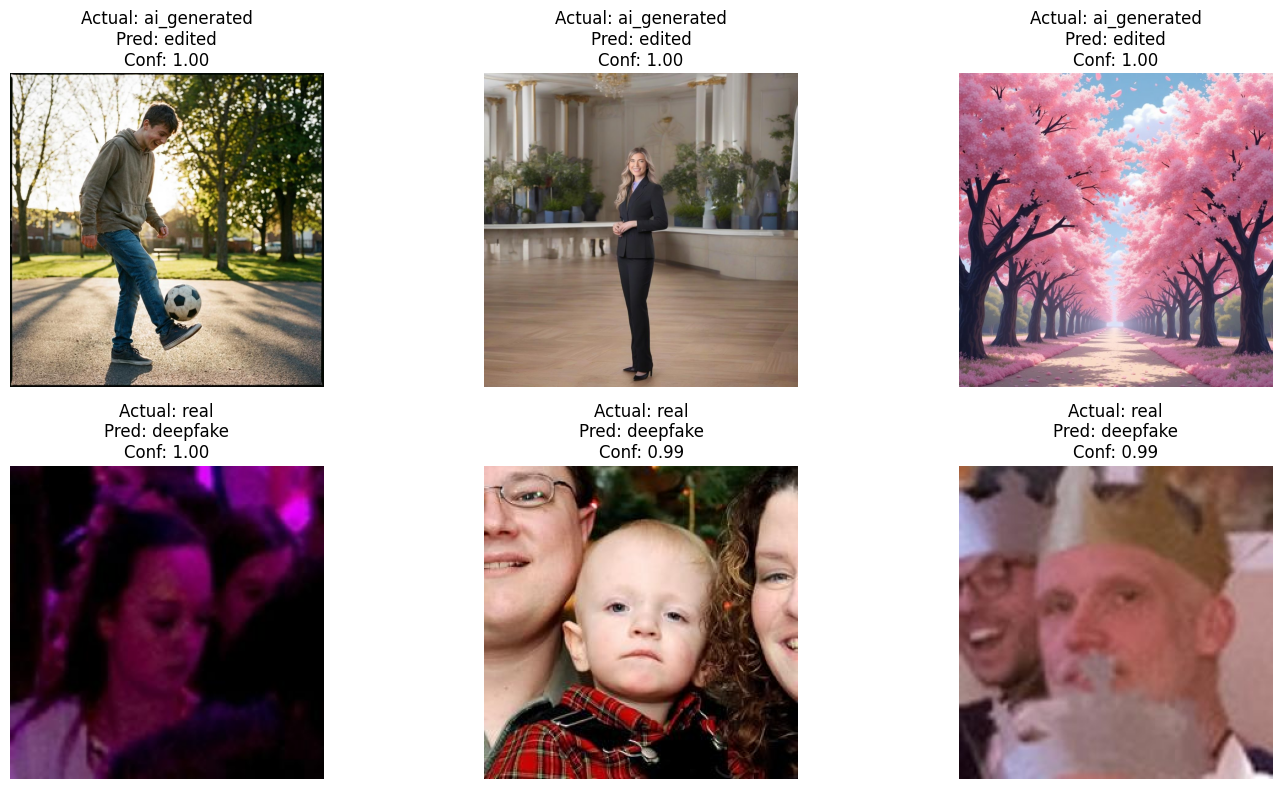


=== Proposed Model: Top Wrong Predictions ===


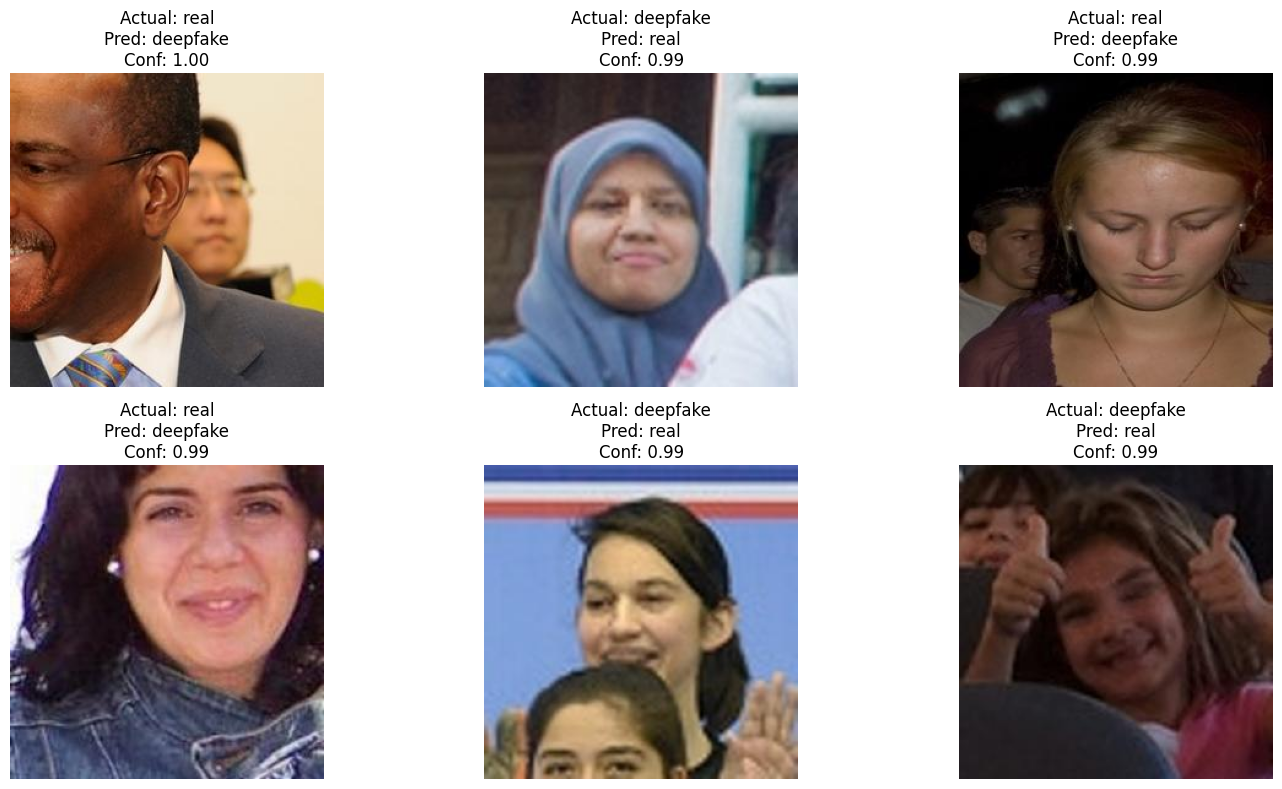

In [38]:
def show_top_wrong_images(probs, preds, y_true, image_paths, num_images=6):
    confidences = np.max(probs, axis=1)

    wrong_indices = np.where(preds != y_true)[0]
    sorted_wrong = wrong_indices[np.argsort(-confidences[wrong_indices])]
    selected = sorted_wrong[:num_images]

    plt.figure(figsize=(15, 8))

    for i, idx in enumerate(selected):
        img = Image.open(image_paths[idx]).convert("RGB")

        plt.subplot(2, 3, i+1)
        plt.imshow(img)
        plt.axis("off")

        plt.title(
            f"Actual: {CLASS_NAMES[y_true[idx]]}\n"
            f"Pred: {CLASS_NAMES[preds[idx]]}\n"
            f"Conf: {confidences[idx]:.2f}"
        )

    plt.tight_layout()
    plt.show()


print("=== Baseline: Top Wrong Predictions ===")
show_top_wrong_images(baseline_probs_norm, baseline_preds_norm, y_true_norm, image_paths_norm)

print("\n=== Proposed Model: Top Wrong Predictions ===")
show_top_wrong_images(proposed_probs_norm, proposed_preds_norm, y_true_norm, image_paths_norm)

In [44]:
import cv2

class GradCAM:
    def __init__(self, model):
        self.model = model
        self.gradients = None
        self.activations = None

        self.target_layer = model.features[6]

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()

        output = self.model(input_tensor)
        loss = output[0, class_idx]
        loss.backward()

        gradients = self.gradients[0].detach().cpu().numpy()
        activations = self.activations[0].detach().cpu().numpy()

        weights = np.mean(gradients, axis=(1, 2))

        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = np.maximum(cam, 0)
        cam = cam / (cam.max() + 1e-8)

        return cam

In [49]:
def show_gradcam_examples(model, probs, preds, y_true, image_paths, num_images=4):
    grad_cam = GradCAM(model)

    wrong_indices = np.where(preds != y_true)[0]

    print(f"Total wrong predictions: {len(wrong_indices)}")

    if len(wrong_indices) == 0:
        print("No wrong predictions found.")
        return

    selected = wrong_indices[:num_images]

    plt.figure(figsize=(12, 6))

    for i, idx in enumerate(selected):
        try:
            img = Image.open(image_paths[idx]).convert("RGB")

            transform = transforms.Compose([
                transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]
                )
            ])

            input_tensor = transform(img).unsqueeze(0).to(device)

            cam = grad_cam.generate(input_tensor, preds[idx])

            cam = cv2.resize(cam, (IMAGE_SIZE, IMAGE_SIZE))
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

            heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
            heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

            img_np = np.array(img.resize((IMAGE_SIZE, IMAGE_SIZE)))

            overlay = (0.6 * img_np + 0.4 * heatmap).astype(np.uint8)

            plt.subplot(2, 2, i+1)
            plt.imshow(overlay)
            plt.axis("off")

            plt.title(
                f"True: {CLASS_NAMES[y_true[idx]]}\n"
                f"Pred: {CLASS_NAMES[preds[idx]]}"
            )

        except Exception as e:
            print(f"Error at index {idx}: {e}")

    plt.tight_layout()
    plt.show()

=== Grad-CAM: Baseline ===
Total wrong predictions: 56


c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\.venv\lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


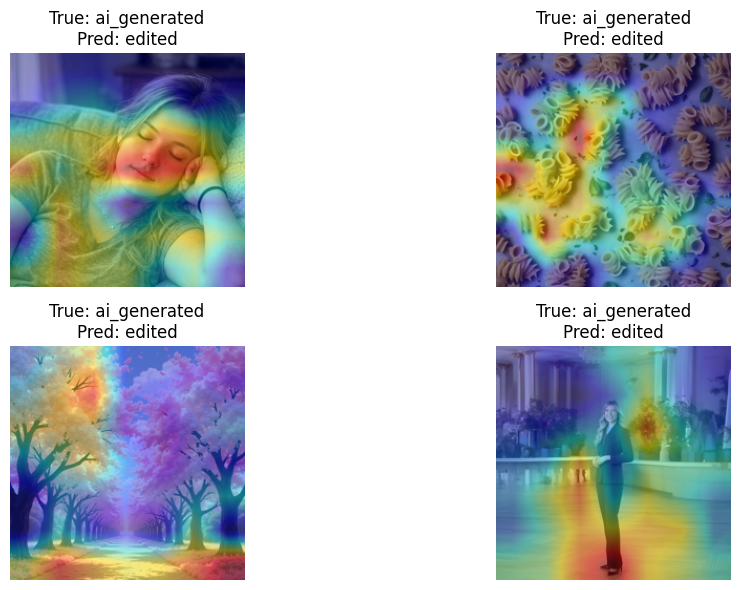


=== Grad-CAM: Proposed ===
Total wrong predictions: 147


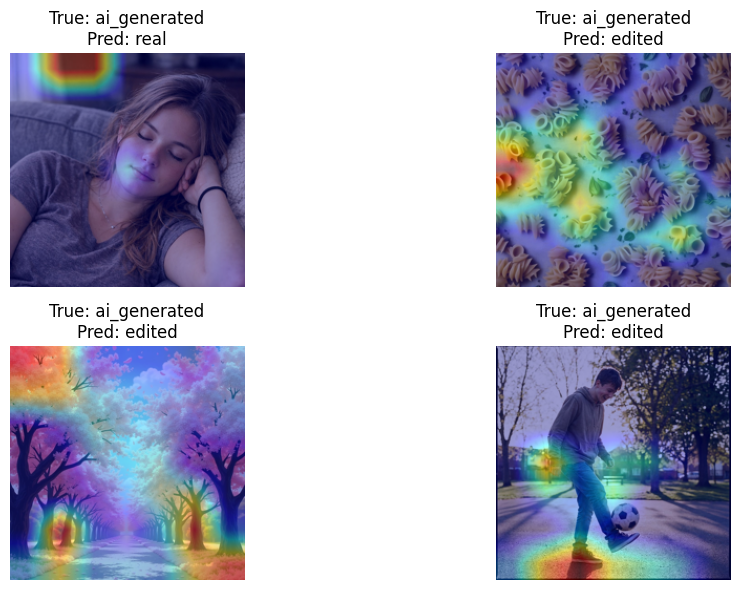

In [50]:
print("=== Grad-CAM: Baseline ===")
show_gradcam_examples(baseline_model, baseline_probs_norm, baseline_preds_norm, y_true_norm, image_paths_norm)

print("\n=== Grad-CAM: Proposed ===")
show_gradcam_examples(proposed_model, proposed_probs_norm, proposed_preds_norm, y_true_norm, image_paths_norm)

In [51]:
def get_top_error_pair(cm, class_names):
    best_pair = None
    best_count = -1

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if i != j and cm[i, j] > best_count:
                best_count = cm[i, j]
                best_pair = f"{class_names[i]} → {class_names[j]}"

    return best_pair, best_count


baseline_top_pair, baseline_top_count = get_top_error_pair(baseline_cm, CLASS_NAMES)
proposed_top_pair, proposed_top_count = get_top_error_pair(proposed_cm, CLASS_NAMES)

final_summary_df = pd.DataFrame([
    {
        "Model": "Baseline EfficientNet-B0",
        "Backbone": "EfficientNet-B0",
        "Classifier Head": "1280 → 4",
        "Accuracy": accuracy_score(y_true_norm, baseline_preds_norm),
        "Weighted F1": precision_recall_fscore_support(
            y_true_norm, baseline_preds_norm, average="weighted", zero_division=0
        )[2],
        "Avg Wrong Confidence": np.max(baseline_probs_norm, axis=1)[baseline_preds_norm != y_true_norm].mean(),
        "Top Error Pair": baseline_top_pair,
        "Top Error Count": baseline_top_count
    },
    {
        "Model": "Proposed Model",
        "Backbone": "EfficientNet-B0",
        "Classifier Head": "1280 → 256 → 4",
        "Accuracy": accuracy_score(y_true_norm, proposed_preds_norm),
        "Weighted F1": precision_recall_fscore_support(
            y_true_norm, proposed_preds_norm, average="weighted", zero_division=0
        )[2],
        "Avg Wrong Confidence": np.max(proposed_probs_norm, axis=1)[proposed_preds_norm != y_true_norm].mean(),
        "Top Error Pair": proposed_top_pair,
        "Top Error Count": proposed_top_count
    }
])

for col in ["Accuracy", "Weighted F1", "Avg Wrong Confidence"]:
    final_summary_df[col] = final_summary_df[col].map(lambda x: f"{x:.4f}")

print("=== Final Baseline vs Proposed Summary ===")
display(final_summary_df)

=== Final Baseline vs Proposed Summary ===


,Model,Backbone,Classifier Head,Accuracy,Weighted F1,Avg Wrong Confidence,Top Error Pair,Top Error Count
0,Baseline EfficientNet-B0,EfficientNet-B0,1280 → 4,0.9823,0.9822,0.8293,deepfake → real,23
1,Proposed Model,EfficientNet-B0,1280 → 256 → 4,0.9536,0.9539,0.7106,real → deepfake,66


In [52]:
print("=== Final Conclusion ===\n")

print("1. The baseline EfficientNet-B0 achieved higher overall accuracy and weighted F1-score.")
print("2. The proposed model used the same EfficientNet-B0 backbone but a deeper classifier head (1280 → 256 → 4).")
print("3. The baseline model showed stronger raw classification performance on this test set.")
print("4. The proposed model remained competitive, but introduced more confusion between real and deepfake samples.")
print("5. Confidence-score analysis showed that the proposed model was less overconfident on wrong predictions.")
print("6. Grad-CAM visualizations showed that both models focused on semantically meaningful image regions such as faces, textures, and manipulated-looking areas.")
print("7. Overall, the baseline model performed better quantitatively, while the proposed model contributed architectural experimentation and interpretability insights.")

=== Final Conclusion ===

1. The baseline EfficientNet-B0 achieved higher overall accuracy and weighted F1-score.
2. The proposed model used the same EfficientNet-B0 backbone but a deeper classifier head (1280 → 256 → 4).
3. The baseline model showed stronger raw classification performance on this test set.
4. The proposed model remained competitive, but introduced more confusion between real and deepfake samples.
5. Confidence-score analysis showed that the proposed model was less overconfident on wrong predictions.
6. Grad-CAM visualizations showed that both models focused on semantically meaningful image regions such as faces, textures, and manipulated-looking areas.
7. Overall, the baseline model performed better quantitatively, while the proposed model contributed architectural experimentation and interpretability insights.
